In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

import matplotlib.pyplot as plt
from xgboost import XGBClassifier
import joblib

In [2]:
df = pd.read_csv("RA_ML_Coded_1.csv")
X = df.drop('RA', axis=1)
y = df['RA']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

train_data = pd.concat([X_train, y_train], axis=1)
test_data = pd.concat([X_test, y_test], axis=1)

train_data.to_csv("RA_Training_Data.csv", index=False)
test_data.to_csv("RA_Testing_Data.csv", index=False)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)


Training shape: (320, 18)
Testing shape: (80, 18)


In [3]:
print(df['RA'].value_counts())
print(y_train.value_counts())
print(y_test.value_counts())

RA
1    200
0    200
Name: count, dtype: int64
RA
1    160
0    160
Name: count, dtype: int64
RA
0    40
1    40
Name: count, dtype: int64


In [4]:
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

In [5]:
param_grid = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}
grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs= 1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(grid_search.best_score_)

Fitting 5 folds for each of 540 candidates, totalling 2700 fits
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.6; total time=   0.0s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.6; total time=   0.0s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.6; total time=   0.0s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.6; total time=   0.0s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.6; total time=   0.0s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.1s
[CV] END colsample_bytree=0.6, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.0s
[CV] END

In [6]:
best_model = grid_search.best_estimator_

joblib.dump(best_model, "Best_XGBoost_Model.pkl")

['Best_XGBoost_Model.pkl']

In [7]:
y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:,1]

cm = confusion_matrix(y_test, y_pred)

TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

specificity = TN / (TN + FP)

f1 = f1_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_prob)


In [8]:
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}")

Accuracy    : 0.8875
Precision   : 0.8444
Recall      : 0.9500
Specificity : 0.8250
F1 Score    : 0.8941
ROC-AUC     : 0.9838


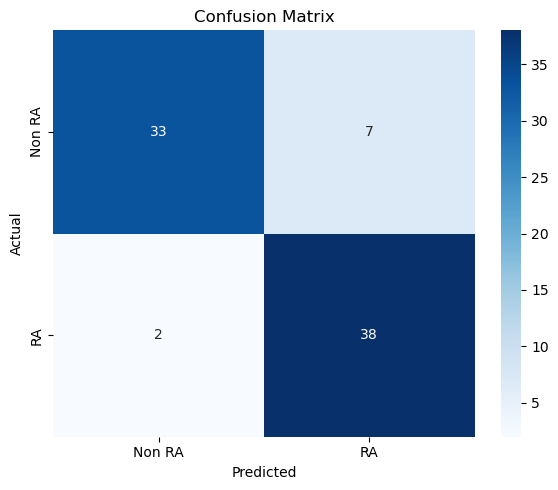

In [12]:
import seaborn as sns

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non RA', 'RA'],
    yticklabels=['Non RA', 'RA']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig("Confusion_Matrix_XGB.png", dpi=300)

plt.show()

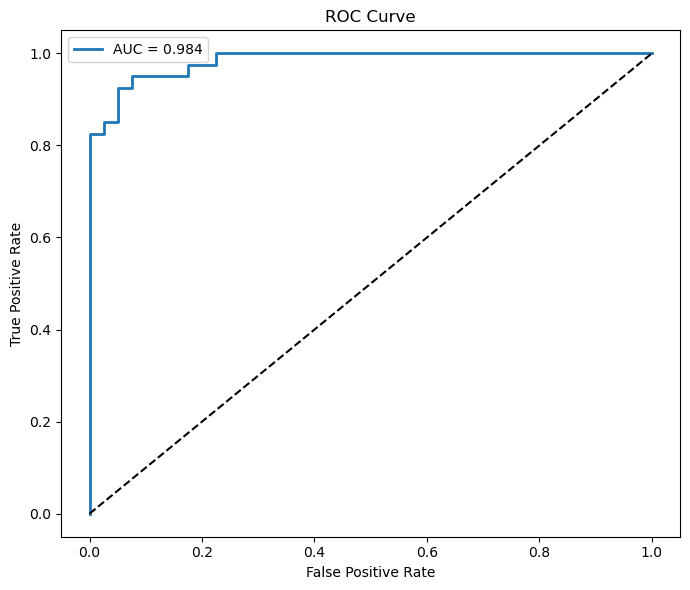

In [10]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'AUC = {roc_auc:.3f}'
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.tight_layout()

plt.savefig("ROC_Curve_XGB.png", dpi=300)

plt.show()

In [11]:
results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'Specificity',
        'F1 Score',
        'ROC-AUC'
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

results.to_csv("XGBoost_Results.csv", index=False)